# Hasil Proyek Klasifikasi Kepuasan Pengguna E-Wallet

Notebook ini menyajikan hasil evaluasi model **Random Forest** yang sudah dilatih di `main.ipynb`. Model dibaca dari file `.pkl`, sehingga tidak perlu dilatih ulang. **Jalankan `main.ipynb` terlebih dahulu** agar file model tersedia.

## 1. Persiapan dan Memuat Artefak
Data uji dibuat ulang dengan pembagian 80:20, `stratify`, dan `random_state=42` agar identik dengan notebook utama.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

RANDOM_STATE = 42
LABEL = ["Kurang Puas", "Cukup Puas", "Puas"]

df = pd.read_csv("data/penggunaan_ewallet_indonesia_5000.csv")
df["Rasio_Cashback"] = df["Total_Cashback_Diterima"] / df["Total_Pengeluaran_Bulanan"]

model = joblib.load("model_kepuasan_rf.pkl")
kolom = joblib.load("kolom_fitur.pkl")

X = df[kolom]
y = df["Tingkat_Kepuasan"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
y_pred = model.predict(X_test)
print("Model dimuat. Jumlah data uji:", len(X_test))

Model dimuat. Jumlah data uji: 1000


## 2. Classification Report
`Precision` = ketepatan prediksi, `recall` = cakupan data pada tiap kelas, `F1-score` = rangkuman keduanya.

In [2]:
rep = classification_report(y_test, y_pred, labels=LABEL, output_dict=True, zero_division=0)
display(pd.DataFrame(rep).T.round(4))

,precision,recall,f1-score,support
Kurang Puas,0.1049,0.1485,0.1230,101.000
Cukup Puas,0.3175,0.3390,0.3279,295.000
Puas,0.6162,0.5530,0.5829,604.000
accuracy,0.4490,0.4490,0.4490,0.449
macro avg,0.3462,0.3468,0.3446,1000.000
weighted avg,0.4765,0.4490,0.4612,1000.000


## 3. Confusion Matrix
Diagonal = prediksi benar; di luar diagonal = kelas yang tertukar.

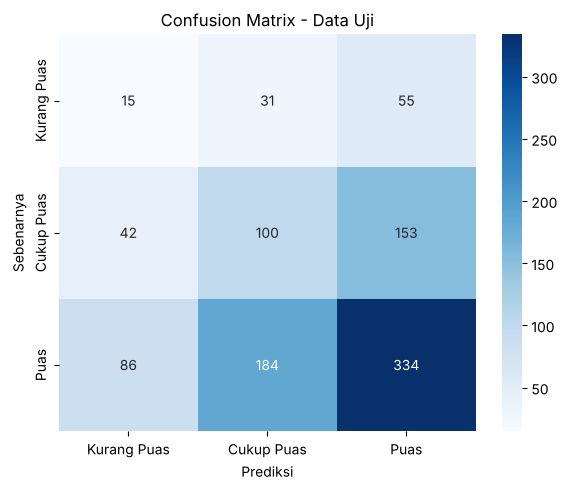

In [3]:
cm = confusion_matrix(y_test, y_pred, labels=LABEL)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABEL, yticklabels=LABEL)
plt.xlabel("Prediksi"); plt.ylabel("Sebenarnya")
plt.title("Confusion Matrix - Data Uji")
plt.tight_layout()
plt.show()

## 4. Feature Importance

,Kepentingan
Total_Cashback_Diterima,0.1679
Rasio_Cashback,0.1672
Rata2_Belanja_Per_Trx,0.1614
Jumlah_Transaksi_Bulanan,0.1372
Usia,0.1335
Jenis_Kelamin_Perempuan,0.0197
E_Wallet_Utama_DANA,0.0196
Jenis_Kelamin_Laki-laki,0.0195
E_Wallet_Utama_GoPay,0.0193
Kota_Jakarta,0.0172


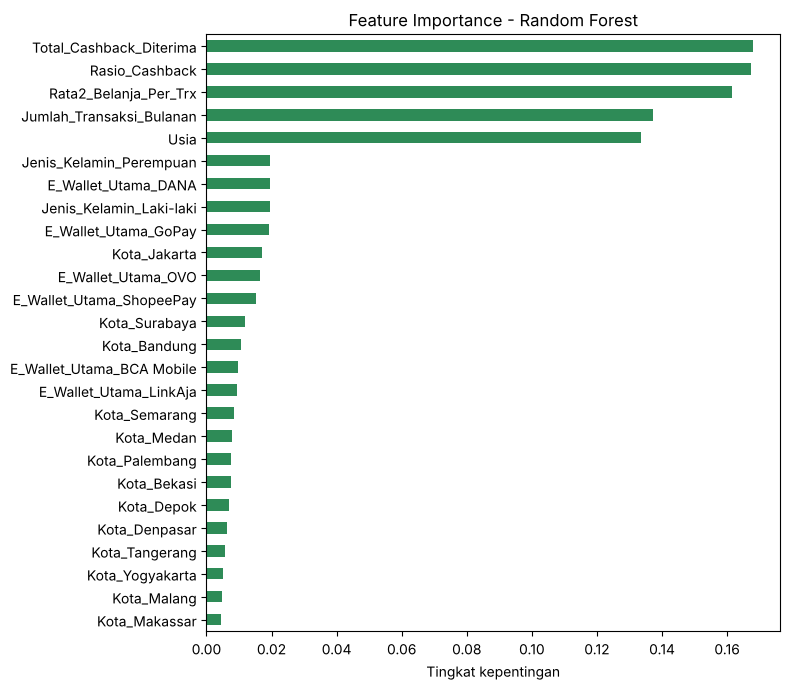

In [4]:
nama = [n.split("__", 1)[1] for n in model.named_steps["prep"].get_feature_names_out()]
imp = pd.Series(model.named_steps["clf"].feature_importances_, index=nama).sort_values()
display(imp.sort_values(ascending=False).rename("Kepentingan").to_frame().round(4).head(10))

plt.figure(figsize=(8, 7))
imp.plot(kind="barh", color="seagreen")
plt.title("Feature Importance - Random Forest")
plt.xlabel("Tingkat kepentingan")
plt.tight_layout()
plt.show()

## 5. Contoh Prediksi
Ubah nilai input untuk mencoba pengguna lain.

In [5]:
baru = pd.DataFrame([{
    "Kota": "Bandung", "Usia": 25, "Jenis_Kelamin": "Laki-laki",
    "E_Wallet_Utama": "DANA", "Jumlah_Transaksi_Bulanan": 40,
    "Rata2_Belanja_Per_Trx": 150000, "Total_Cashback_Diterima": 180000,
}])
baru["Rasio_Cashback"] = baru["Total_Cashback_Diterima"] / (
    baru["Jumlah_Transaksi_Bulanan"] * baru["Rata2_Belanja_Per_Trx"])
baru = baru[kolom]

print("Prediksi:", model.predict(baru)[0])
print(pd.Series(model.predict_proba(baru)[0], index=model.classes_).round(3).sort_values(ascending=False))

Prediksi: Puas
Puas           0.444
Cukup Puas     0.355
Kurang Puas    0.201
dtype: float64


## 6. Kesimpulan
Ringkasan dihitung langsung dari data uji saat notebook dijalankan, dibandingkan dengan baseline yang selalu menebak kelas terbanyak.

In [6]:
acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="macro")
base = y_test.value_counts(normalize=True).max()

print(f"Accuracy Random Forest : {acc:.2%} pada {len(X_test):,} data uji")
print(f"Macro-F1               : {f1:.4f}")
print(f"Accuracy baseline      : {base:.2%} (selalu menebak 'Puas')")
print(f"Selisih terhadap baseline: {(acc - base) * 100:+.2f} poin persen")
print("Fitur terpenting:", ", ".join(imp.sort_values(ascending=False).head(3).index))
if acc <= base + 0.02:
    print("\nCatatan: model tidak berbeda berarti dari baseline, sehingga fitur yang ada "
          "tampaknya tidak cukup informatif untuk memprediksi kepuasan.")

Accuracy Random Forest : 44.90% pada 1,000 data uji
Macro-F1               : 0.3446
Accuracy baseline      : 60.40% (selalu menebak 'Puas')
Selisih terhadap baseline: -15.50 poin persen
Fitur terpenting: Total_Cashback_Diterima, Rasio_Cashback, Rata2_Belanja_Per_Trx

Catatan: model tidak berbeda berarti dari baseline, sehingga fitur yang ada tampaknya tidak cukup informatif untuk memprediksi kepuasan.
